In [6]:
import sys
!{sys.executable} -m pip install pyspark==3.5.1


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: /usr/local/opt/python@3.10/bin/python3.10 -m pip install --upgrade pip


In [7]:
import pyspark
print(pyspark.__version__)

3.5.1


In [8]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Music Analysis") \
    .getOrCreate()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/04/15 22:48:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [9]:
df = spark.read.csv("dataset.csv", header=True, inferSchema=True)

In [10]:
df.createOrReplaceTempView("songs")

In [11]:
from pyspark.sql import SparkSession

spark = SparkSession.builder \
    .appName("Music Analysis") \
    .getOrCreate()

df = spark.read.csv("dataset.csv", header=True, inferSchema=True)

df.show(5)
df.printSchema()

+---+--------------------+--------------------+--------------------+--------------------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-------+--------------+-----------+
|_c0|            track_id|             artists|          album_name|          track_name|popularity|duration_ms|explicit|danceability|energy|key|loudness|mode|speechiness|acousticness|instrumentalness|liveness|valence|  tempo|time_signature|track_genre|
+---+--------------------+--------------------+--------------------+--------------------+----------+-----------+--------+------------+------+---+--------+----+-----------+------------+----------------+--------+-------+-------+--------------+-----------+
|  0|5SuOikwiRyPMVoIQD...|         Gen Hoshino|              Comedy|              Comedy|        73|     230666|   False|       0.676| 0.461|  1|  -6.746|   0|      0.143|      0.0322|         1.01E-6|   0.358|  0.715| 87.917|           4

26/04/15 22:48:51 WARN CSVHeaderChecker: CSV header does not conform to the schema.
 Header: , track_id, artists, album_name, track_name, popularity, duration_ms, explicit, danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo, time_signature, track_genre
 Schema: _c0, track_id, artists, album_name, track_name, popularity, duration_ms, explicit, danceability, energy, key, loudness, mode, speechiness, acousticness, instrumentalness, liveness, valence, tempo, time_signature, track_genre
Expected: _c0 but found: 
CSV file: file:///Users/nguyenthiphuong/Documents/VsCode/dataset.csv


In [33]:
# chuan hoa ten cot
df.columns

['_c0',
 'track_id',
 'artists',
 'album_name',
 'track_name',
 'popularity',
 'duration_ms',
 'explicit',
 'danceability',
 'energy',
 'key',
 'loudness',
 'mode',
 'speechiness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'valence',
 'tempo',
 'time_signature',
 'track_genre']

In [12]:
df = df.withColumnRenamed("genre", "track_genre")

In [13]:
# tao bang SQL
df.createOrReplaceTempView("songs")

In [14]:
# cau truy van 1: Dem so bai hat theo the loai
spark.sql("""
SELECT track_genre, COUNT(*) AS so_luong
FROM songs
GROUP BY track_genre
ORDER BY so_luong DESC
""").show()

+-----------+--------+
|track_genre|so_luong|
+-----------+--------+
|    country|    1000|
|     french|    1000|
|       club|    1000|
|     groove|    1000|
|  dancehall|    1000|
|alternative|    1000|
|    ambient|    1000|
|death-metal|    1000|
|      blues|    1000|
|   alt-rock|    1000|
|      dance|    1000|
|   children|    1000|
| deep-house|    1000|
|black-metal|    1000|
|  bluegrass|    1000|
|   afrobeat|    1000|
|       goth|    1000|
|     comedy|    1000|
|  breakbeat|    1000|
|       folk|    1000|
+-----------+--------+
only showing top 20 rows



In [37]:
# cau truy van 2: Top 10 bai hat pho bien nhat
spark.sql("""
SELECT track_name, artists, popularity
FROM songs
ORDER BY popularity DESC
LIMIT 10
""").show(truncate=False)

[Stage 39:>                                                         (0 + 1) / 1]

+----------+------------------------------------------------------+---------------------+
|track_name|artists                                               |popularity           |
+----------+------------------------------------------------------+---------------------+
| Vol.2""" |Alireza Mashayekhi;Djamchid Chemirani;Keyvan Chemirani|Zendani              |
| Vol.2""" |Alireza Mashayekhi;Layla Ramezan                      |The Wait             |
| Vol.2""" |Alireza Mashayekhi;Layla Ramezan                      |The Mirage           |
| Vol.2""" |Alireza Mashayekhi;Layla Ramezan                      |The Fury             |
| Vol. 3)" |Winifred Atwell                                       |Taquinez les touches!|
| Vol.2""" |Alireza Mashayekhi;Djamchid Chemirani;Keyvan Chemirani|Shekast              |
| Vol.2""" |Alireza Mashayekhi;Djamchid Chemirani;Keyvan Chemirani|Sarab                |
| Pt. 1"   |Bill Haley                                            |Rock Around the Clock|
| Vol.2"""

In [38]:
#Cau 3: Thong ke theo the loai
spark.sql("""
SELECT track_genre,
       COUNT(*) AS so_luong,
       AVG(popularity) AS popularity_tb
FROM songs
GROUP BY track_genre
ORDER BY popularity_tb DESC
""").show()

+-----------------+--------+------------------+
|      track_genre|so_luong|     popularity_tb|
+-----------------+--------+------------------+
|         pop-film|     998|59.287575150300604|
|            k-pop|    1000|            56.896|
|            chill|    1000|            53.651|
|              sad|    1000|            52.379|
|           grunge|    1000|            49.594|
|           indian|    1000|            49.539|
|            anime|    1000|            48.772|
|              emo|    1000|            48.128|
|        sertanejo|    1000|            47.866|
|              pop|    1000|            47.576|
|progressive-house|    1000|            46.615|
|            piano|    1000|            45.273|
|         mandopop|    1000|            45.025|
|       deep-house|    1000|            44.808|
|           brazil|    1000|             44.67|
|       electronic|    1000|            44.325|
|           pagode|    1000|            44.298|
|          ambient|    1000|            

In [39]:
#Cau 4: Thong ke theo nghe si
spark.sql("""
SELECT artists,
COUNT(*) AS so_luong,
AVG(popularity) AS popularity_tb
FROM songs
GROUP BY artists
ORDER BY so_luong DESC
""").show()


[Stage 43:>                                                         (0 + 1) / 1]

+--------------------+--------+------------------+
|             artists|so_luong|     popularity_tb|
+--------------------+--------+------------------+
|         The Beatles|     279|61.007168458781365|
|        George Jones|     271|16.505535055350553|
|       Stevie Wonder|     236|1.0635593220338984|
|         Linkin Park|     224| 56.07142857142857|
|     Ella Fitzgerald|     222|0.7342342342342343|
|       Prateek Kuhad|     217| 46.33179723502304|
|                Feid|     202|10.084158415841584|
|         Chuck Berry|     190| 7.873684210526315|
|     Håkan Hellström|     183| 31.48633879781421|
|         OneRepublic|     181|30.861878453038674|
|      The Beach Boys|     176| 7.329545454545454|
|   my little airport|     171| 33.21637426900585|
|       Elvis Presley|     169|55.071005917159766|
|   Charlie Brown Jr.|     169| 42.22485207100592|
|Red Hot Chili Pep...|     159|41.132075471698116|
|         Bryan Adams|     157|10.993630573248408|
|             Scooter|     155|

In [40]:
df = df.withColumnRenamed("track_genre", "genre")
df.createOrReplaceTempView("songs")

In [41]:
#Cau 5: Tim cac the loai energy va danceability trung binh cao nhat

spark.sql("""
SELECT genre,
       AVG(energy) AS energy_tb,
       AVG(danceability) AS danceability_tb
FROM songs
GROUP BY genre
ORDER BY energy_tb DESC, danceability_tb DESC
""").show()

+-----------------+------------------+-------------------+
|            genre|         energy_tb|    danceability_tb|
+-----------------+------------------+-------------------+
|            0.103|          175066.0|               21.0|
|            0.114|          130840.0|               21.0|
|             0.34|              25.0|               NULL|
|      death-metal|0.9314700000000008| 0.3684109000000002|
|        grindcore|0.9242010000000016| 0.2718537000000001|
|        metalcore|0.9144849999999995|0.42380000000000007|
|            happy|0.9109710000000006|           0.552847|
|        hardstyle|0.9012460000000007| 0.5392289999999997|
|    drum-and-bass|0.8766350000000008| 0.5354859999999997|
|      black-metal|0.8748973000000019| 0.2964108999999997|
|      heavy-metal|0.8740029999999996| 0.4284996999999999|
|            party|0.8712370000000005|           0.667191|
|           j-idol|0.8686772999999997| 0.5488190000000002|
|       industrial|0.8617452999999998| 0.530415999999999

In [42]:
# Ve do thi cho cau truy van 5' Tim cac the loai energy va danceability trung binh cao nhat

df_plot = spark.sql("""
SELECT genre,
       AVG(energy) AS energy_tb,
       AVG(danceability) AS danceability_tb
FROM songs
GROUP BY genre
ORDER BY energy_tb DESC, danceability_tb DESC
""").toPandas()

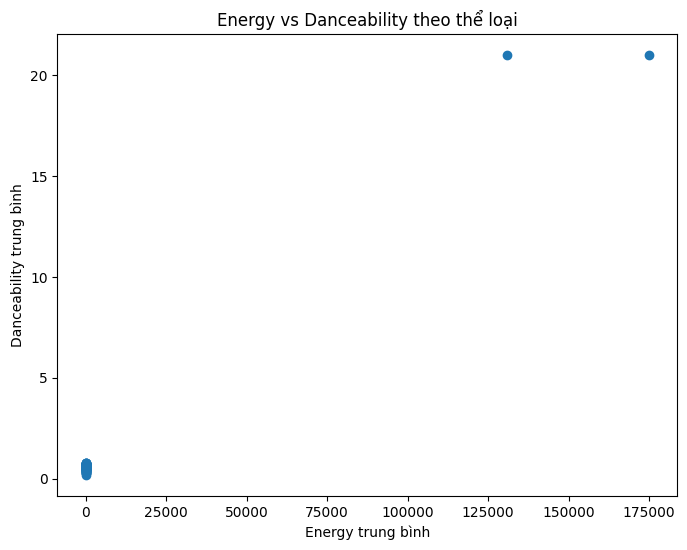

In [43]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(df_plot["energy_tb"], df_plot["danceability_tb"])

plt.xlabel("Energy trung bình")
plt.ylabel("Danceability trung bình")
plt.title("Energy vs Danceability theo thể loại")

plt.show()

In [46]:
# Ve do thi cau 1
df_genre = spark.sql("""
SELECT genre, COUNT(*) AS so_luong
FROM songs
GROUP BY genre
ORDER BY so_luong DESC
""").toPandas()

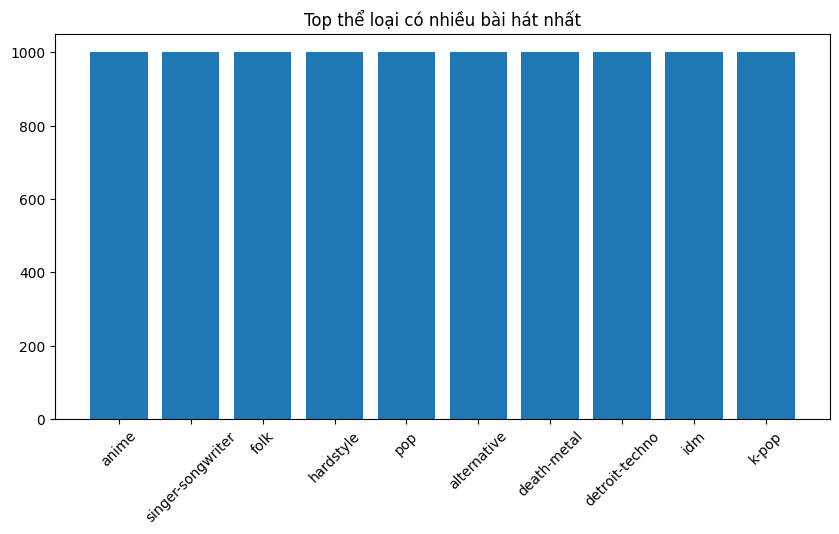

In [47]:
import matplotlib.pyplot as plt

top10 = df_genre.head(10)

plt.figure(figsize=(10,5))
plt.bar(top10["genre"], top10["so_luong"])

plt.xticks(rotation=45)
plt.title("Top thể loại có nhiều bài hát nhất")

plt.show()

In [48]:
# Ve do thi cau truy van 2
df_top10_song = spark.sql("""
SELECT track_name, artists, popularity
FROM songs
ORDER BY popularity DESC
LIMIT 10
""").toPandas()

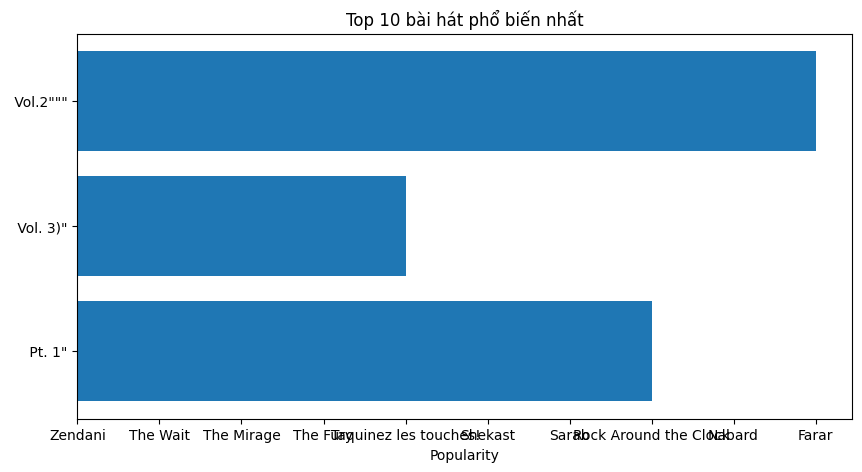

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.barh(df_top10_song["track_name"], df_top10_song["popularity"])

plt.gca().invert_yaxis()
plt.title("Top 10 bài hát phổ biến nhất")
plt.xlabel("Popularity")

plt.show()

In [50]:
# Ve do thi cau truy van 3
df_genre_stats = spark.sql("""
SELECT genre,
       COUNT(*) AS so_luong,
       AVG(popularity) AS popularity_tb
FROM songs
GROUP BY genre
ORDER BY popularity_tb DESC
""").toPandas()

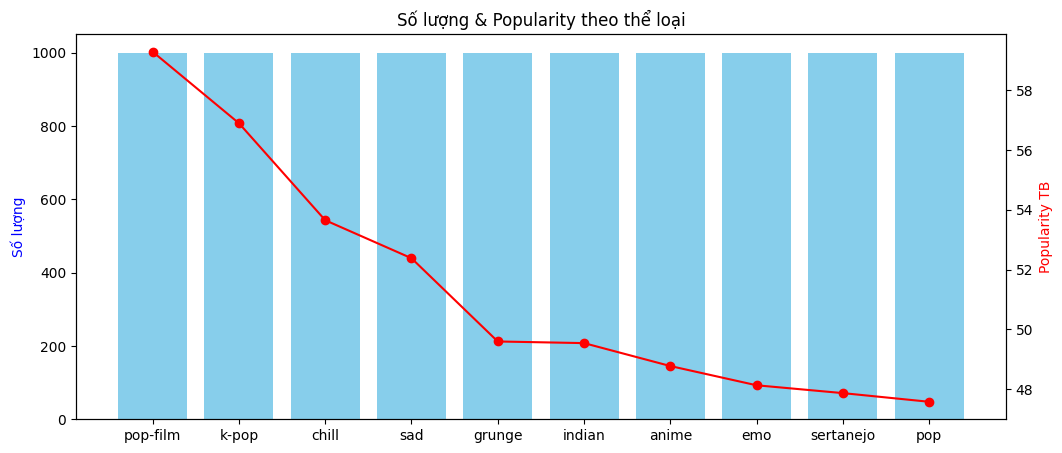

In [51]:
fig, ax1 = plt.subplots(figsize=(12,5))

top10 = df_genre_stats.head(10)

# Bar: số lượng
ax1.bar(top10["genre"], top10["so_luong"], color="skyblue")
ax1.set_ylabel("Số lượng", color="blue")

# Line: popularity
ax2 = ax1.twinx()
ax2.plot(top10["genre"], top10["popularity_tb"], color="red", marker="o")
ax2.set_ylabel("Popularity TB", color="red")

plt.xticks(rotation=45)
plt.title("Số lượng & Popularity theo thể loại")

plt.show()

In [52]:
#Ve bieu do cau truy van 4
from pyspark.sql.functions import split, explode, avg, count

df_artist = df.withColumn("artist", explode(split(df["artists"], ";")))

In [53]:
df_artist_stats = df_artist.groupBy("artist") \
    .agg(
        count("*").alias("so_luong"),
        avg("popularity").alias("popularity_tb")
    ) \
    .orderBy("so_luong", ascending=False) \
    .limit(10) \
    .toPandas()

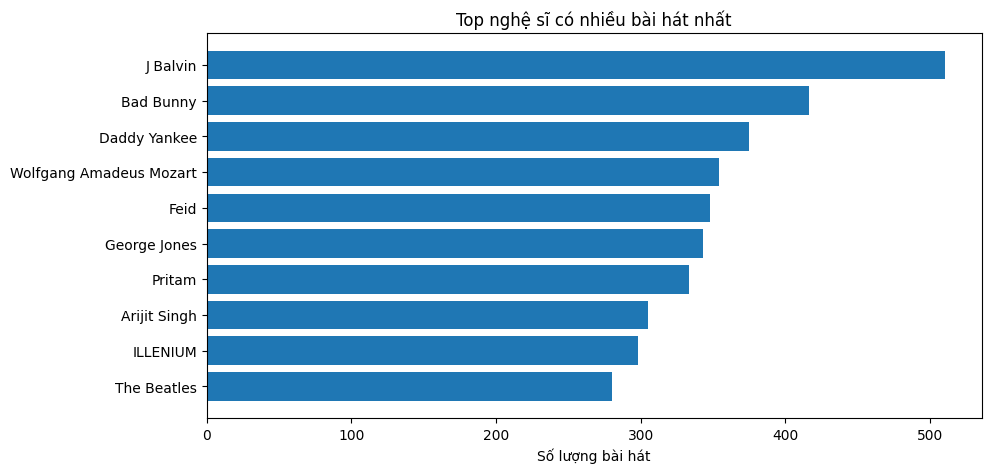

In [54]:
plt.figure(figsize=(10,5))

plt.barh(df_artist_stats["artist"], df_artist_stats["so_luong"])

plt.gca().invert_yaxis()
plt.title("Top nghệ sĩ có nhiều bài hát nhất")
plt.xlabel("Số lượng bài hát")

plt.show()